# convolution

Let's start by reading in the data

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data = np.loadtxt("signal.txt")

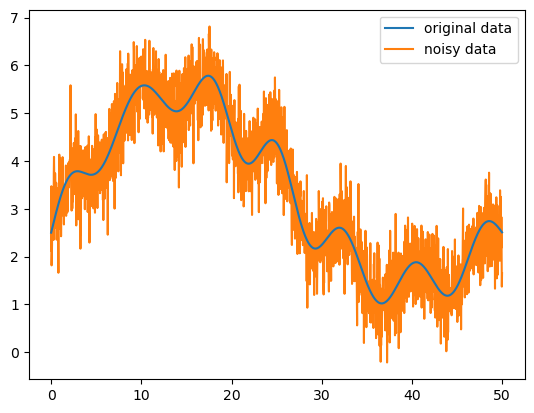

In [4]:
fig, ax = plt.subplots()

ax.plot(data[:,0], data[:,1], label="original data", zorder=100)
ax.plot(data[:,0], data[:,2], label="noisy data")
ax.legend()

We want to do our best to recover the original data from the noisy signal.

In [5]:
x = data[:, 0]
original = data[:, 1]
signal = data[:, 2]

Let's define our smoothing function&mdash;a Gaussian.  We add the function to itself with stride `-` to get something that is symmetric.

In [6]:
def gaussian(x, sigma=0.5):
    """ a gaussian kernel """

    g = 1.0/(sigma*np.sqrt(2.0*np.pi))*np.exp(-0.5*(x/sigma)**2)
    g = g[:] + g[::-1]
    gsum = np.sum(g)
    return g/gsum

In [7]:
kernel = gaussian(x)

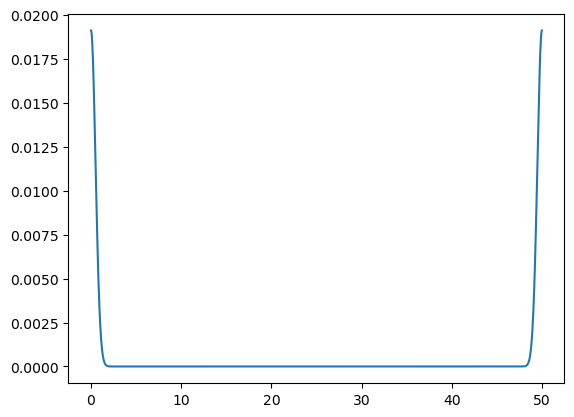

In [8]:
fig, ax = plt.subplots()

ax.plot(x, kernel)

We can see that the amplitude is also quite low&mdash;we normalized it such that the discrete data sums to 1 over the domain.

Now let's take the FFT of both the signal and kernel

In [9]:
fft_signal = np.fft.rfft(signal)
fft_kernel = np.fft.rfft(kernel)

The convolution is just the product of the transforms

In [10]:
conv = fft_signal * fft_kernel

Now let's transform back

In [11]:
smoothed = np.fft.irfft(conv).real

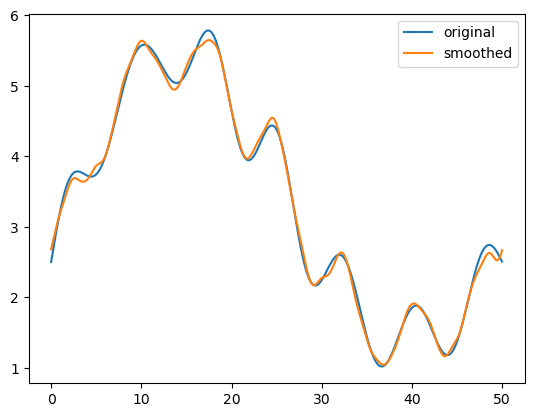

In [12]:
fig, ax = plt.subplots()
ax.plot(x, original, label="original")
ax.plot(x, smoothed, label="smoothed")
ax.legend()

We see that the smoothed data looks quite clean and agrees with the original data very well.

In [13]:
from scipy.signal import convolve

In [27]:
sigma = 0.5
kernel2 = 1.0/(sigma*np.sqrt(2.0*np.pi))*np.exp(-0.5*((x-x.max()/2)/sigma)**2)

In [31]:
filtered = convolve(signal, kernel2, mode="same") / sum(kernel)

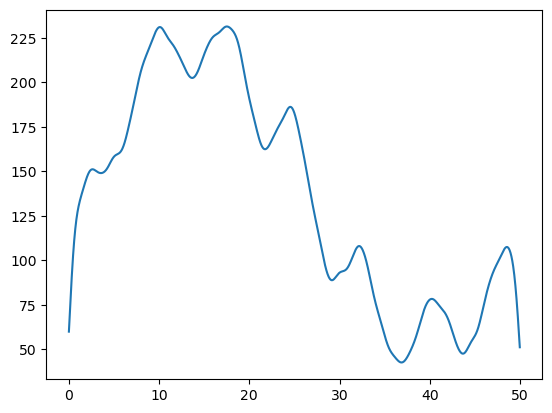

In [32]:
fig, ax = plt.subplots()
ax.plot(x, filtered)

In [17]:
x.shape

(2048,)

In [19]:
filtered.shape

(4095,)